<a href="https://colab.research.google.com/github/CZH1113/liking-gap/blob/main/Copy_of_Simple_PIERRE.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Implementation of Simple PIERRE in Python

Note: For this small inspiring set loading from a string is more convenient in Colab but for your own projects you will likely use an external file.

NOTE：！！！



*   recipes
    - name


    - ingredients （g）
      - unit
      - 1000 unit
        - 直接套pierre soup菜单里设置的总量 1000g的话， 需要算所有原料之间的比例关系。一旦厨子用的材料总量不是1000g或者更换其他食材种类就得重新算比例。不如直接以面粉这一最大原料为baseline（所有蛋糕配方刚需），只用计算其他原料和面粉配比即可。
    - baking time （min）
    - stirring time （min）
      - 我后来查了一下，蓬松度跟烤制时间和打发时间没太大关系，影响蓬松度的因素是膨松剂含量、酸碱配比、面粉类型和打发方式，这两个时间可以在算法里作为常数，不参与进化，只在cookbook里根据一般菜谱简单写一下就行（类似pierre里假设所有汤都用同一套"慢炖锅8小时"的做法，只进化食材的做法，代换到咱们的方案：固定基础面糊，把creativity集中在风味和质地的探索上→constrained creativity）

* 评分表

  1.软硬度softness（占50%）： 越松软/越接近膨松剂和面粉完美比例分数越高  
    - baking powder
    - baking soda
    - stirring time
      -  小苏打必须和酸一起反应才会蓬松（stirring time那条建议里的酸碱配比就是说的这个），没果酸参与的话会苦也不蓬松，所以可以设定“有小苏打 → 检查是否有酸性食材，没有就扣分；或者更简单一点，直接用泡打粉，因为泡打粉不需要酸反应，只规定泡打粉和面粉的配比即可，这样后续也不用考虑水果酸度的计算，更简洁

  2.口味flavors（占40%）：

  2.1 清新度 freshness (mint,)  有薄荷加分，越多越高（占30分） →”越清新分越高“最后可能把薄荷拉满变成牙膏味蛋糕，发苦。或许可以放宽对”清新“的界定，比如香茅、罗勒、青柠皮？

  2.2 sugar（占20分）
  - \<5% ;
  - 5-20% 最优;
  - \>20;
  
    - 问题：5–20% 都给满分，算法在这个区间里感觉不到任何差别，考61分和89都一样的待遇，进化可能受限。而且水果本身含糖，还得转换含糖量。
    - 方法一：细分含糖量的梯度+转化水果糖分计入总含糖量，但是这样会比较麻烦。
    - 方法二：和面粉的思路一样，把糖固定为面粉的某个百分比，排除在变异之外，不参与打分，只是作为配方原料常数，这样也不用考虑果糖转化（毕竟糖也不是影响风味的主要因素）
  

  2.3 热带水果种类（占50分）
  - 越多越好  种类越多越好
    - 凡是"越多越好"的项，进化几代之后都会加满，只奖励好，不奖励新，最优后代都高度相似，缺少novelty和”意料之外“？而且没有限制水果总量，算法想继续加分，唯一的办法是把水果总量一起往上堆 → 热带水果多一份，就再配一份普通水果。最后水果越堆越多，水分含量过多根本没法蓬松，会变成水果捞。得在这里加硬性约束条件，全部水果 ≤ 面粉的 X%。
  - 数量不超过5种/热带水果在总水果的总比重 <50%
    - 还是>50%吧，毕竟热带口味是主打，如果其他水果超过一半，就不是热带风味主导了
    - 另外还需要规定水果形态，是鲜果、果脯、果干还是果粉？得转为统一的衡量→鲜果当量（相当于多少克鲜果"，再统一打分），但那样还是太麻烦了，所以干脆直接规定成只用鲜果吧


  3.有无视觉装饰物decoration （占10%）
  - 有就给分- eg 糖霜 椰蓉 可可粉 小伞. 小樱桃 柠檬片
    - "有就给分"又变成了常数送分题，轮了几代之后都有装饰，这项分数等于没有。
    - 方法一：能吃的且符合热带风情的装饰才加分（小伞这类不能吃的/奶油/西方传统香草棒这种没分）；
    - 方法二：在看眷茶、瑞幸、霸王茶姬这些菜谱的时候深受启发！！！荆芥柠檬、酱香拿铁、桂花乌龙，这些风味的思路都是某种文化的典型风味食材融到到另一种文化的制作方式里（knowledge transfer）
      - novelty1:例如荆芥是最能代表河南味道的一种调料，主要用来做凉拌菜，没人想过能用来做茶饮，它就跟饮料压根八竿子打不着（类似小葱泡茶），但是跟柠檬茶饮搭在一起碰撞出极其清新甚至很有攻击性的清爽，我爱死，目前是我心理最能代表河南的味道！
      - novelty 2:酱香拿铁也是同样的思路，中式白酒+西式咖啡，两种单独拆开来看在某种文化里再寻常不过的食材和做法，但是没人会想过迁移在一起。
      - novelty3:桂花乌龙虽然不是迁移，但是给了另一个思路：增加风味层次的除了口味还有香气！如果把清新度freshness或者decoration的评分换热带香草/香粉应该能够极大的刺激和丰富感官（味觉+嗅觉），对于后期storytelling的cookbook会增加很多代入感和沉浸感


**固定结构**
- 蛋糕胚：黄油、糖、蛋、面粉（低筋）= 1:1:1:1
- 水果类型（共35种，需要贴标签ture/false）：
  - 热带水果： 百香果、菠萝、番石榴、莲雾、蛇皮果、龙眼、杨桃、菠萝蜜、芒果、榴莲、火龙果、红毛丹、荔枝、木瓜、山竹、释迦果、香蕉、青柠
  
  - 普通水果：无花果、苹果、梨、蓝莓、覆盆子、蔓越莓、枇杷、石榴、沙棘、橙子、草莓、葡萄、桃子、李子、哈密瓜、奇异果、西瓜
- 香型：
  - 草本花香型
      - 薄荷、荆芥、罗勒、佛手柑、班兰、香茅、疯柑叶、蝶豆花、栀子、茉莉、洛神花、玫瑰
  - 东方茶香型
      - 乌龙、龙井、白茶、抹茶
  - 厚重香型
      - 可可、巧克力、肉桂、丁香、豆蔻、姜、八角、甘草
- 装饰
  - 食用型
    - 桃胶、陈皮、西米、珍珠、青柠皮、樱桃、椰蓉、蝶豆花、糖霜、奶油、香草棒、芝麻、薄荷、罗勒、班兰、巧克力碎
  - 热带风情型
    - 姜花、兰花、鸡蛋花、芭蕉叶、青柠皮、薄荷、罗勒、班兰、椰蓉、蝶豆花、西米、珍珠、牙签小伞、椰树模型

---

**评分表 fitness = 0.30 × 蓬松度 + 0.30 × 口味 + 0.20 × 香气 + 0.10 × 装饰 + 0.10 × 新颖度**（每一项先算成 0–1 的分数，再乘权重。不给 0 分的选项，进化会很快把它淘汰，种群多样性就没了。"不太好"给低分，不给零分。）

- **蓬松度fluffiness（占30% ）= 0.5 × 泡打粉分 + 0.5 × 打发方式分（三选一）**
  - 区间划定：range_score（泡打粉%，3.3, 5.0）→ 3.3%下限，5%上限，可以取任意值，越偏离这个区间分数越低
  - 打发方式：METHOD_SCORE = {
    "separated_whites": 1.0,
    "whole_egg":        0.7,
    "creaming_butter":  0.4,
}


- **口味分（占30%）= 0.3 × 种类分 + 0.4 × 热带比例分 + 0.3 × 用量分**
  - 种类分（按不同水果计数，同一种水果只算一次）：
    - 种类数	0，1，2，	3–4，5，6+
    - 得分	  0， 0.2，0.6，1.0，0.6，0.2

  - 热带比例分 r= 热带水果占所有水果搭配的占比>50% = 热带水果种类数 ÷ 全部水果种类数（需要给每种水果打上热带水果true/false的标签）
    - 分数换算（目标：热带超过一半）
      - r ≥ 0.7 → 1.0
      - 0.5 ≤ r < 0.7 → 0.6 + (r − 0.5) × 2，从 0.6 线性升到 1.0
      - r < 0.5 → r × 1.2
  - 用量分 = 水果跟面粉比重的不超过50%，区间划定： range_score(水果总量占面粉%, 20, 50),→ 20%下限，50%上限


- **香气分（占20%）= 数量系数 × (0.4 × 类别分 + 0.3 × 用量分 + 0.3 × 搭配分)**
  - 数量系数：1-2种香气最优（所以后面搭配分只考虑1-2种香味的得分）
    - 香气食材数	0，1，2，	3，	4+
    - 系数	0，	1.0，1.0，	0.5，	0
  - 类别分（0.4）- 主打草本*东方香调
     - 草本花香型	1.0
     - 东方茶香型	0.8
     - 厚重香型	0.2
  - 用量分（0.3）- 每种香粉跟面粉的比例区间
    - range_score(用量占面粉%, 0.5, 1)； 0.5%下限，1%上限
  - 搭配分（0.3）-香型之间搭不搭
    - 只有一种香气的时候得分为1.0（就一种香，不存在搭不搭的问题）；
    - 2种香味的时候：
      - 花+茶得分最高=1.0（eg 班兰白茶），
      - 花+花稍低=0.8（重复单一但依旧符合热带调性，eg 玫瑰茉莉）
      - 茶+厚重=0.7，（常见，但不一定符合调性，eg 抹茶巧克力）
      - 茶+茶 = 厚重+厚重 = 0.6（重复且不符合热带调性，eg 白茶乌龙）
      - 花+厚重 = 0.4（或许会出惊喜，所以保留种群生存空间，eg 玫瑰丁香）
    
- **装饰分（占10%）= 数量系数 × 各件单件分的平均**
  - 数量系数：1-2件最好
    - 件数	0，1，2，3，4+
    - 系数	0，1.0，1.0，0.7，0.4
  - 各件单件分= 可食用和热带风情各加0.5
  * decorations=['coconut flaks', 'cherry'] ## add any decoration item to this list
  * edible=['','']？
  * tropical=['','']？ *italicized text*

- **新颖度/创新性迁移（占10%） = 0.6 × rare 2-gram 比例 + 0.4 × 迁移分**
  - rare 2-gram 比例 = 罕见配对数 ÷ 总配对数
    - 把配方里所有进化层食材两两配对（芒果–茉莉、茉莉–白茶……），数有多少对在西式 inspiring set 里从没一起出现过（Morris et al. (2012)的方法）
  - 迁移分 = min(1, 迁移配对数 ÷ 2)：有 2 对就满分
    - 准备一份东方风味搭配表（第二 inspiring set）：茉莉–白茶、班兰–椰子、香茅–青柠、荆芥–青柠……）配方里的某个配对在西式集里没有、在东方表里有 → 算一次迁移


重复项规则：层内重复只算一次分，跨蹭重复允许多几累加（eg.香味层里有薄荷，装饰上还有薄荷，属于合理的风味呼应，而且两层各自有数量上限，进化刷不了分）


#knowledgebase

In [10]:
data = """{
  "fruit": [
    { "name": "passion fruit",        "tropical": true },
    { "name": "pineapple",            "tropical": true },
    { "name": "guava",                "tropical": true },
    { "name": "wax apple",            "tropical": true },
    { "name": "salak",                "tropical": true },
    { "name": "starfruit",            "tropical": true },
    { "name": "jackfruit",            "tropical": true },
    { "name": "mango",                "tropical": true },
    { "name": "durian",               "tropical": true },
    { "name": "dragon fruit",         "tropical": true },
    { "name": "rambutan",             "tropical": true },
    { "name": "lychee",               "tropical": true },
    { "name": "papaya",               "tropical": true },
    { "name": "mangosteen",           "tropical": true },
    { "name": "sugar apple",          "tropical": true },
    { "name": "banana",               "tropical": true },
    { "name": "longan",               "tropical": true },
    { "name": "avocado",              "tropical": true },
    { "name": "fig",                  "tropical": false },
    { "name": "apple",                "tropical": false },
    { "name": "pear",                 "tropical": false },
    { "name": "blueberry",            "tropical": false },
    { "name": "raspberry",            "tropical": false },
    { "name": "cranberry",            "tropical": false },
    { "name": "loquat",               "tropical": false },
    { "name": "pomegranate",          "tropical": false },
    { "name": "sea buckthorn",        "tropical": false },
    { "name": "orange",               "tropical": false },
    { "name": "strawberry",           "tropical": false },
    { "name": "grape",                "tropical": false },
    { "name": "peach",                "tropical": false },
    { "name": "plum",                 "tropical": false },
    { "name": "hami melon",           "tropical": false },
    { "name": "kiwi",                 "tropical": false },
    { "name": "watermelon",           "tropical": false },
    { "name": "lime",                 "tropical": false },
    { "name": "lemon",                "tropical": false },
    { "name": "pomelo",               "tropical": false },
    { "name": "grapefruit",           "tropical": false }
  ],
  "aroma": [
    { "name": "mint",                 "category": "floral" },
    { "name": "jingjie",              "category": "floral" },
    { "name": "basil",                "category": "floral" },
    { "name": "bergamot",             "category": "floral" },
    { "name": "pandan",               "category": "floral" },
    { "name": "lemongrass",           "category": "floral" },
    { "name": "gardenia",             "category": "floral" },
    { "name": "jasmine",              "category": "floral" },
    { "name": "kaffir lime leaf",     "category": "floral" },
    { "name": "butterfly pea",        "category": "floral" },
    { "name": "hibiscus",             "category": "floral" },
    { "name": "rose",                 "category": "floral" },
    { "name": "orange",               "category": "floral" },
    { "name": "lemon",                "category": "floral" },
    { "name": "osmanthus",            "category": "floral" },
    { "name": "perilla",              "category": "floral" },
    { "name": "rosemary",             "category": "floral" },
    { "name": "oolong powder",        "category": "tea" },
    { "name": "longjing powder",      "category": "tea" },
    { "name": "white tea powder",     "category": "tea" },
    { "name": "matcha",               "category": "tea" },
    { "name": "green tea powder",     "category": "tea" },
    { "name": "jasmine tea powder",   "category": "tea" },
    { "name": "earl grey",            "category": "tea" },
    { "name": "cocoa",                "category": "heavy" },
    { "name": "chocolate",            "category": "heavy" },
    { "name": "cinnamon",             "category": "heavy" },
    { "name": "clove",                "category": "heavy" },
    { "name": "cardamom",             "category": "heavy" },
    { "name": "ginger",               "category": "heavy" },
    { "name": "star anise",           "category": "heavy" },
    { "name": "licorice",             "category": "heavy" },
    { "name": "nutmeg",               "category": "heavy" },
    { "name": "almond",               "category": "heavy" }
  ],
  "decoration": [
    { "name": "lime",                 "tropical": true,   "edible": true },
    { "name": "mint",                 "tropical": true,   "edible": true },
    { "name": "basil",                "tropical": true,   "edible": true },
    { "name": "pandan",               "tropical": true,   "edible": true },
    { "name": "coconut",              "tropical": true,   "edible": true },
    { "name": "butterfly pea",        "tropical": true,   "edible": true },
    { "name": "sago",                 "tropical": true,   "edible": true },
    { "name": "tapioca pearls",       "tropical": true,   "edible": true },
    { "name": "water chestnut",       "tropical": true,   "edible": true },
    { "name": "aloe",                 "tropical": true,   "edible": true },
    { "name": "peach gum",            "tropical": false,  "edible": true },
    { "name": "dried tangerine peel", "tropical": false,  "edible": true },
    { "name": "cherry",               "tropical": false,  "edible": true },
    { "name": "icing",                "tropical": false,  "edible": true },
    { "name": "whipped cream",        "tropical": false,  "edible": true },
    { "name": "vanilla bean",         "tropical": false,  "edible": true },
    { "name": "sesame",               "tropical": false,  "edible": true },
    { "name": "chocolate",            "tropical": false,  "edible": true },
    { "name": "lemon",                "tropical": false,  "edible": true },
    { "name": "goji",                 "tropical": false,  "edible": true },
    { "name": "red bean",             "tropical": false,  "edible": true },
    { "name": "job's tears",          "tropical": false,  "edible": true },
    { "name": "rose",                 "tropical": false,  "edible": true },
    { "name": "jelly cubes",          "tropical": false,  "edible": true },
    { "name": "perilla",              "tropical": false,  "edible": true },
    { "name": "edible gold foil",     "tropical": false,  "edible": true },
    { "name": "ginger flower",        "tropical": true,   "edible": false },
    { "name": "orchid",               "tropical": true,   "edible": false },
    { "name": "frangipani",           "tropical": true,   "edible": false },
    { "name": "banana leaf",          "tropical": true,   "edible": false },
    { "name": "cocktail umbrella",    "tropical": true,   "edible": false },
    { "name": "palm tree topper",     "tropical": true,   "edible": false },
    { "name": "bamboo leaf",          "tropical": true,   "edible": false }
  ]
}"""

import json
kb = json.loads(data)

# 按"层 + 名字"查属性，例如 ING[("aroma", "lemon")]["category"] -> "floral"
ING = {(layer, item["name"]): item for layer, items in kb.items() for item in items}

FRUITS      = [i["name"] for i in kb["fruit"]]
AROMAS      = [i["name"] for i in kb["aroma"]]
DECORATIONS = [i["name"] for i in kb["decoration"]]

print(len(FRUITS), len(AROMAS), len(DECORATIONS))   # 39 34 33

39 34 33


#Inspiring Set





In [11]:
import json
import pprint
import random
import math

In [12]:
import csv, io

def parse(cell):
    """'lemon:74; mint' -> {'lemon': 74.0, 'mint': None}"""
    out = {}
    for item in str(cell).split(';'):
        item = item.strip()
        if not item:
            continue
        name, _, amt = item.partition(':')
        out[name.strip()] = float(amt) if amt.strip() else None
    return out

RECIPES_CSV = """name,url,method,flour_g,baking_powder_g,bp_percent,fruits,aromas,decorations
Glazed Lemon Bundt Cake,https://www.kingarthurbaking.com/recipes/glazed-lemon-bundt-cake-recipe,creaming_butter,360,8,2.22,lemon:74,lemon:4,icing
Lemonade Cake,https://www.kingarthurbaking.com/recipes/lemonade-cake-recipe,creaming_butter,360,10,2.78,lemon:30,,icing
Honey Lemon Cake,https://www.kingarthurbaking.com/recipes/honey-lemon-cake-recipe,creaming_butter,180,2,1.11,lemon:14.8,lemon:8,icing
Rich and Tender Banana Cake,https://www.kingarthurbaking.com/recipes/rich-and-tender-banana-cake-recipe,creaming_butter,180,2,1.11,banana:171,,icing
King Arthur's Original Pound Cake,https://www.kingarthurbaking.com/recipes/king-arthurs-original-pound-cake-recipe,creaming_butter,240,6,2.5,,,
Chocolate Pound Cake,https://www.kingarthurbaking.com/recipes/chocolate-pound-cake-recipe,creaming_butter,180,4,2.22,,cocoa:42,
Coconut Layer Cake,https://www.kingarthurbaking.com/recipes/coconut-layer-cake-recipe,creaming_butter,400,14,3.5,,,icing; coconut
Glazed Berry Bundt Cake,https://www.kingarthurbaking.com/recipes/glazed-berry-bundt-cake-recipe,creaming_butter,360,8,2.22,blueberry:175; raspberry:175; strawberry:175,,mint
Golden Vanilla Pound Cake,https://www.kingarthurbaking.com/recipes/golden-vanilla-pound-cake-recipe,creaming_butter,226,4,1.77,,,icing
Devil's Food Cake,https://www.kingarthurbaking.com/recipes/devils-food-cake-recipe,creaming_butter,240,8,3.33,,cocoa:64,icing
Lemon Chiffon Cake,https://www.kingarthurbaking.com/recipes/lemon-chiffon-cake-recipe,separated_whites,240,12,5.0,lemon:15.3,,lemon
Chiffon Cake,https://www.kingarthurbaking.com/recipes/chiffon-cake-recipe,separated_whites,240,10,4.17,,,icing
Double Chocolate Chiffon Cake,https://www.kingarthurbaking.com/recipes/double-chocolate-chiffon-cake-recipe,separated_whites,210,10,4.76,,cocoa:49,icing
Lychee Raspberry Chiffon Cake,https://www.sugarologie.com/recipes/lychee-raspberry-chiffon-cake,separated_whites,180,8,4.44,lychee:140; raspberry:120,almond:5,rose; butterfly pea
Meyer Lemon Chiffon Cake,https://www.kingarthurbaking.com/recipes/meyer-lemon-chiffon-cake-recipe,separated_whites,106,0,0.0,lemon:71,lemon,lemon
Pandan Chiffon Cake,https://www.kingarthurbaking.com/recipes/pandan-chiffon-cake-recipe,separated_whites,200,4,2.0,,pandan,
Orange Chiffon Cake,https://www.justonecookbook.com/orange-chiffon-cake/,separated_whites,75,4,5.33,orange:60,cardamom:1,
Matcha Chiffon Cake,https://www.justonecookbook.com/green-tea-chiffon-cake/,separated_whites,75,4,5.33,,matcha:8,
Earl Grey Chiffon Cake,https://www.justonecookbook.com/earl-grey-chiffon-cake/,separated_whites,75,4,5.33,,earl grey:3,
Chocolate Chiffon Cake,https://www.justonecookbook.com/chocolate-chiffon-cake/,separated_whites,80,5,6.25,,cocoa:40,
Earl Grey Tea Cake,https://www.indulgewithmimi.com/earl-grey-tea-cake-roll/,separated_whites,45,4,8.89,,earl grey:3,
Mango Mousse Cake,https://www.indulgewithmimi.com/chinese-bakery-mango-mousse-cake/#mv-creation-133-jtr,separated_whites,112,4,3.57,mango:300,,edible gold foil
Sponge Cake with Cranberry Curd,https://www.kingarthurbaking.com/recipes/sponge-cake-with-cranberry-curd-recipe,separated_whites,120,0,0.0,cranberry:348; orange:75,,whipped cream
Berry Tiramisu,https://www.kingarthurbaking.com/recipes/berry-tiramisu-recipe,whole_egg,120,4,3.33,blueberry; raspberry; strawberry; lemon:74,clove:1,lemon
Strawberry Cream Cake,https://www.kingarthurbaking.com/recipes/strawberry-cream-cake-recipe,whole_egg,168,3,1.79,strawberry:396,,whipped cream
Caramel Peach Upside-Down Cake,https://www.kingarthurbaking.com/recipes/caramel-peach-upside-down-cake-recipe,whole_egg,90,0,0.0,peach:300,,whipped cream
Genoise,https://www.kingarthurbaking.com/recipes/genoise-recipe,whole_egg,90,0,0,,,lemon
Jelly Roll,https://www.kingarthurbaking.com/recipes/jelly-roll-recipe,whole_egg,90,3,3.33,,,icing
Chef Zeb's Hot Milk Cake,https://www.kingarthurbaking.com/recipes/chef-zebs-hot-milk-cake-recipe,whole_egg,240,8,3.33,,,
Classic Birthday Cake,https://www.kingarthurbaking.com/recipes/classic-birthday-cake-recipe,whole_egg,240,8,3.33,,cocoa:106,icing
Boston Cream Pie,https://www.kingarthurbaking.com/recipes/boston-cream-pie-recipe,whole_egg,240,8,3.33,,chocolate:57,icing
Tres Leches Cake,https://www.kingarthurbaking.com/recipes/tres-leches-cake-recipe,separated_whites,180,8,4.44,,almond:4,whipped cream
Low Sugar Pandan Chiffon Cake,https://bakeomaniac.com/low-sugar-pandan-chiffon-cake-recipe/,separated_whites,120,4,3.33,,pandan:4,"""

RECIPES = []
for r in csv.DictReader(io.StringIO(RECIPES_CSV)):
    RECIPES.append({
        "name": r["name"], "url": r["url"], "method": r["method"],
        "flour_g": float(r["flour_g"]), "baking_powder_g": float(r["baking_powder_g"]),
        "bp_percent": float(r["bp_percent"]),
        "fruit": parse(r["fruits"]), "aroma": parse(r["aromas"]), "decoration": parse(r["decorations"]),
    })

# 检查：所有食材都在清单里
for rec in RECIPES:
    for layer in ("fruit", "aroma", "decoration"):
        for name in rec[layer]:
            assert (layer, name) in ING, (rec["name"], layer, name)
print(len(RECIPES), "recipes OK")

33 recipes OK


# oriental tea


In [13]:
EAST_CSV = """name,region/brand,source,fruits,aromas,decorations,items
椰汁西米糕 Coconut sago cake,Southern China,https://m.xiachufang.com/recipe/101806426/,,,sago; water chestnut; pandan; coconut,sago; water chestnut; pandan; coconut
班兰千层糕  Kuih Lapis,southeastern Asia,https://m.xiachufang.com/recipe/103890798/,,pandan,pandan; coconut,pandan; coconut
海南清补凉 Qing bu liang,"Hainan,China",https://m.xiachufang.com/recipe/100534741/,watermelon; pineapple; mango,,red bean; job's tears,watermelon; pineapple; mango; red bean; job's tears
云南鲜花饼 Yunnan rose flower cake,"Yunnan, China",https://m.xiachufang.com/recipe/106819217/,lemon,rose,sesame; rose,lemon; rose; sesame
Kue putu,Indonesia,https://kab-nduga.kpu.go.id/blog/read/9371_resep-membuat-kue-putu-cara-mudah-membuat-jajanan-tradisional-yang-legit-wangi-dan-lembut,,pandan,coconut; bamboo leaf,pandan; coconut
Chè Thái,Vietnam,https://www.cooking-therapy.com/che-thai/,jackfruit; longan; lychee; strawberry,,water chestnut; jelly cubes; tapioca pearls,jackfruit; longan; lychee; strawberry; water chestnut; jelly cubes; tapioca pearls
杨枝甘露 Mango pomelo sago,"Hong Kong, China",https://m.xiachufang.com/recipe/17713/,mango; pomelo,,sago,mango; pomelo; sago
桂花糕 / 桂花冻 Osmanthus jelly,Southern China,https://www.greedygirlgourmet.com/osmanthus-flower-tea-konnyaku-jelly-%e6%a1%82%e8%8a%b1%e7%b3%95-gui-hua-gao-recipe/,,osmanthus; jasmine,goji,osmanthus; jasmine; goji
桂花荔枝冻芝士蛋糕 Osmanthus lychee jelly cheesecake,southeastern Asia,https://themeatmen.sg/osmanthus-lychee-jelly-cheesecake/,lychee,osmanthus,goji,lychee; osmanthus; goji
香茅荔枝冻 Lemongrass lychee jelly,southeastern Asia,https://www.sidechef.com/recipes/13289/?print=1,lychee; lemon,lemongrass,,lychee; lemon; lemongrass
香茅青柠芝士蛋糕 Lemongrass lime cheesecake,southeastern Asia,https://www.sidechef.com/recipes/13288/?print=1,lime,lemongrass; kaffir lime leaf,,lime; lemongrass; kaffir lime leaf
Es Teler,Indonesia,https://en.wikipedia.org/wiki/Es_teler,avocado; jackfruit,pandan,,avocado; jackfruit; pandan
Halo-halo,the Philippines,https://www.sbs.com.au/food/recipes/halo-halo-1,banana; jackfruit,pandan,coconut; cherry,banana; jackfruit; pandan; coconut; cherry
Chè bưởi,Vietnam,https://www.sbs.com.au/food/recipe/vietnamese-pomelo-rind-pudding/e2jrz4nmi,pomelo,pandan,,pomelo; pandan
strawberry peach green tea,喜茶,https://www.heytea.com/products,strawberry; peach,green tea powder,tapioca pearls,strawberry; peach; green tea powder; tapioca pearls
grape green tea,喜茶,https://www.heytea.com/products,grape,green tea powder,,grape; green tea powder
mango grapefruit green tea,喜茶,https://www.heytea.com/products,mango; grapefruit,green tea powder,sago,mango; grapefruit; green tea powder; sago
lychee white tea,喜茶,https://www.heytea.com/products,lychee; dragon fruit,white tea powder,aloe,lychee; dragon fruit; white tea powder; aloe
jingjie lemonade,眷茶,http://www.juancha.com.cn/,lemon,jingjie; jasmine,lime,lemon; jingjie; jasmine; lime
purple perilla lemonade,眷茶,http://www.juancha.com.cn/,lime,perilla; hibiscus; rose,dried tangerine peel; perilla,lime; perilla; hibiscus; rose; dried tangerine peel
pomegranate jasmine tea,眷茶,http://www.juancha.com.cn/,pomegranate,jasmine; jasmine tea powder,,pomegranate; jasmine; jasmine tea powder
watermelon mint juice,眷茶,http://www.juancha.com.cn/,watermelon,mint,,watermelon; mint
passion fruit rosemary oolong tea ,眷茶,http://www.juancha.com.cn/,passion fruit; orange,rosemary; oolong powder,,passion fruit; orange; rosemary; oolong powder"""

EAST = []
for r in csv.DictReader(io.StringIO(EAST_CSV)):
    EAST.append({
        "name": r["name"], "source": r["region/brand"], "url": r["source"],
        "fruit": parse(r["fruits"]), "aroma": parse(r["aromas"]), "decoration": parse(r["decorations"]),
        "items": [x.strip() for x in r["items"].split(";") if x.strip()],
    })

# 东方表里出现过的所有两两组合
import itertools
EAST_PAIRS = {tuple(sorted(p)) for d in EAST for p in itertools.combinations(set(d["items"]), 2)}
print(len(EAST), "east dishes,", len(EAST_PAIRS), "pairs")

23 east dishes, 109 pairs


## Creating an Initial Population

Now we can create an initial population, by first defining the population size and then selecting from the list of recipes.

In [14]:
population_size = 20

population = random.choices(RECIPES, k=population_size)

## Evaluating Recipes (Fitness Function)

The following function defines how individuals are evaluated:

In [6]:
def evaluate_recipes(recipes):
  for r in recipes:
    r['fitness'] = len(r['ingredients'])

structure of fitness evaluation：



*   decoration score [finished]
*  fragrance score[finished]
* fluffiness [finished]
* flavor. [finished]
* novelty





In [15]:
# -----Decoration part 10%----------

def decorationScore(recipe):
  'for every recipe， to get the full mark， it should include 1-2 decoration item， and moreover， they should be edible and tropical。'
  'step one is to test the diversity of decoration itms； '
  'step two is to test if it is safe to eat'
  'step three is to test if it includes tropical food，'
  newlist=[] ##identified decoration items
  decorationNum=0
  scoreA=0  ## diversity
  scoreB=0 ## speciality

  for name in recipe['decoration']:
      newlist.append(name)

  newlist = list(set(newlist))
  decorationNum = len(newlist)
  if decorationNum==0:
    return 10
  if decorationNum > 0:
    if decorationNum in [1,2]:
      scoreA=1;
    else: scoreA = 1/max(1, decorationNum - 1)

  ## edible / tropical
  for name in newlist:
    if ING[('decoration', name)] ['edible']:
      scoreB+=50;
    if ING[('decoration', name)] ['tropical']:
      scoreB+=50;
    scoreB = min(scoreB, 100)

  ##total score = scoreA * scoreB

  return scoreA * scoreB

print(decorationScore(RECIPES[0]))


50


In [14]:
# -------fragrance score 20% -------
herbalFloral = ["mint", "catnip", "basil", "bergamot", "pandan", "lemongrass", "kaffir lime leaves", "butterfly pea flower", "gardenia", "jasmine", "hibiscus", "rose"]
orientalTea = ["oolong tea", "longjing tea", "white tea", "matcha"]
richSpices = ["cocoa", "chocolate", "cinnamon", "clove", "cardamom", "ginger", "star anise", "licorice"]
fragNum=0

## collect all the fragmence ingredients
def fragranceScore(recipe):
  'total score = diversity score(A) * [0.4* speciality (B) + 0.3 * proportion(C)+ 0.3* match(D)]'
  newlist={}
  scoreA=0
  scoreB=0
  scoreC=0
  scoreD=0
  for i in recipe['ingredients']:
    ingredient = i['ingredient']
    amount=i['amount']

    if i['ingredient'] in herbalFloral + orientalTea + richSpices :
      if i['ingredient'] not in newlist:
        newlist[ingredient] = amount
      else:
        newlist[ingredient]+= amount

  fragNum = len(newlist)


## diversity score (A)
  if fragNum==0:
    return 10
  elif fragNum in [1,2]:
    scoreA=1
  elif fragNum == 3:
    scoreA=0.5;
  elif fragNum >=4:
    return 10

## scoreB : category
  categories =[]
  for ingredient in newlist:
    if ingredient in herbalFloral:
      scoreB += 100
      categories.append('herbal')
    elif ingredient in orientalTea:
      scoreB+=80
      categories.append('tea')
    elif ingredient in richSpices:
      scoreB+=20
      categories.append('rich')


    scoreB=min(100,scoreB)
    print('categories: ', categories)

## scoreC: proportion； fragRatio

  flourAmount = 0
  for i in recipe['ingredients']:
    if i['ingredient'] =='flour':
        flourAmount += i['amount']
  print('flourAmount: ', flourAmount )


  totalFrag = sum(newlist.values())
  fragRatio =totalFrag/flourAmount

  if  0.01<= fragRatio < 0.05:
    scoreC = 100


## scoreD: match or not
  matchRules = {
    ('herbal', 'tea'): 100,
    ("herbal","herbal"): 80,
    ("rich","tea"):70 ,
    ("tea","tea"): 60,
    ("rich","rich"):60,
    ("herbal", "rich"):40
  }

  if fragNum==1:
    scoreD=100
  elif fragNum==2:
    pair=tuple(sorted(categories))
    scoreD=matchRules.get(pair, 0)
  elif fragNum==3:
    scoreD=40


  ## total score
  return scoreA*(0.4*scoreB +0.3*scoreC+0.3*scoreD)



In [ ]:
#---------fluffiness score 30%--------

def fluffinessScore(recipe):
  scoreA=0
  scoreB=0
  'calculate the proportion (powder / flour), ~3.3%-5% best;'
  'method: separated_whites ~ best'
  'total score = 0.5* method (A)+ 0.5*proportion(B) '
  ## method score


  methodType={
      'separated_whites':100,
      'whole_egg':70,
      'creaming_butter':40
  }

  method=recipe['method']
  scoreA=methodType.get(method, 0)

 ## proportion

  flourAmount=0
  powderAmount=0

  for i in recipe['ingredients']:
    if i['ingredient'] == 'flour':
      flourAmount+=i['amount']

    elif i['ingredient']=='powder':
      powderAmount+= i['amount']


  prop=powderAmount/flourAmount;
  if 0.033 <= prop <= 0.05:
    scoreB = 100
  elif prop < 0.033:
    scoreB =(prop/0.033)*100
  elif prop > 0.05:
    scoreB =(0.1-prop)/0.05*100

  scoreB=max(20,scoreB)


  return 0.5*scoreA+0.5*scoreB



In [ ]:
# -------flavor score 30%---------------

fruits = {
    # Tropical fruits (True)
    "passion fruit": True,
    "pineapple": True,
    "guava": True,
    "wax apple": True,
    "snake fruit": True,
    "longan": True,
    "star fruit": True,
    "jackfruit": True,
    "mango": True,
    "durian": True,
    "dragon fruit": True,
    "rambutan": True,
    "lychee": True,
    "papaya": True,
    "mangosteen": True,
    "sugar apple": True,
    "banana": True,
    "lime": True,

    # Non-tropical fruits (False)
    "fig": False,
    "apple": False,
    "pear": False,
    "blueberry": False,
    "raspberry": False,
    "cranberry": False,
    "loquat": False,
    "pomegranate": False,
    "sea buckthorn": False,
    "orange": False,
    "strawberry": False,
    "grape": False,
    "peach": False,
    "plum": False,
    "cantaloupe": False,
    "kiwi": False,
    "watermelon": False
}

def flavorScore(recipe):
  'total score = 0.3* diversity (A) + 0.4*tropical (B) + 0.3* amount (c)'
  newlist=[]
  totalFruitAmount=0
  flourAmount=0

  #collect fruits

  for i in recipe['ingredients']:
    ingredient=i['ingredient']
    amount =i['amount']

    if ingredient in fruits:
      newlist.append(ingredient)
      totalFruitAmount+=amount

    elif ingredient =="flour":
      flourAmount += amount

  newlist=list(set(newlist))
  fruitNum=len(newlist)

  ## diversity score

  if fruitNum == 0:
    return 10 ## the lowest score in fruits part

  elif fruitNum == 1:
    scoreA=20
  elif fruitNum in [2,5]:
    scoreA=60
  elif fruitNum in [3,4]:
    scoreA = 100
  elif fruitNum >= 6:
    scoreA=20

  ## tropical fruit ratio score

  tropicalNum=0
  for fruit in newlist:
    if fruits[fruit] == True:
      tropicalNum+=1

  if fruitNum ==0:
    scoreB=10
  else:
    r = tropicalNum/fruitNum
    if r >= 0.7:
      scoreB=100
    elif r >= 0.5:
      scoreB=(0.6 + (r-0.5)*2) *100
    else:
      scoreB=r*120


  ## fuit amount score

  if flourAmount==0:
    scoreC==0

  else:
    prop=totalFruitAmount/flourAmount
    if 0.2<=prop<=0.5:
      scoreC=100
    elif peop<0.2:
      scoreC=prop/20
    else:
      scoreC=(1-prop)/50

  scoreC= max(0, scoreC)

## total score
  totalScore=0.3*scoreA +0.4*scoreB + 0.3*scoreC
  return totalScore



We can use this to evaluate the initial population.

In [ ]:
evaluate_recipes(population)
population = sorted(population, reverse = True, key = lambda r: r['fitness'])

In [ ]:
pprint.PrettyPrinter(indent=2, depth=2).pprint(population)

[ {'ingredients': [...], 'name': 'corn chowder'},
  {'ingredients': [...], 'name': 'chicken soup'},
  {'ingredients': [...], 'name': 'split pea soup'},
  {'ingredients': [...], 'name': 'mulligatawny soup'},
  {'ingredients': [...], 'name': 'corn chowder'},
  {'ingredients': [...], 'name': 'cabbage soup'},
  {'ingredients': [...], 'name': 'beef chilli'},
  {'ingredients': [...], 'name': 'mulligatawny soup'},
  {'ingredients': [...], 'name': 'butternut squash soup'},
  {'ingredients': [...], 'name': 'mulligatawny soup'},
  {'ingredients': [...], 'name': 'cabbage soup'},
  {'ingredients': [...], 'name': 'butternut squash soup'},
  {'ingredients': [...], 'name': 'butternut squash soup'},
  {'ingredients': [...], 'name': 'beef chilli'},
  {'ingredients': [...], 'name': 'butternut squash soup'},
  {'ingredients': [...], 'name': 'beef chilli'},
  {'ingredients': [...], 'name': 'cabbage soup'},
  {'ingredients': [...], 'name': 'beef chilli'},
  {'ingredients': [...], 'name': 'cabbage soup'},
 

## Selecting Recipes

The following function implements Roulette Wheel selection of individuals based on their fitness:

In [ ]:
def select_recipe(recipes):
  sum_fitness = sum([recipe['fitness'] for recipe in recipes])
  f = random.randint(0, sum_fitness)
  for recipe in recipes:
    if f < recipe['fitness']:
      return recipe
    f -= recipe['fitness']
  return recipes[-1]

## Genetic Operators

The following functions implement the genetic operators of crossover and mutation. Crossover takes two recipes and combines them by choosing a point on each genotype (recipe) to split each list into two, and joining the first sublist from one genotype with the second sublist of the second genotype.

In [ ]:
recipe_number = 1

def crossover_recipes(r1, r2):
  global recipe_number
  p1 = random.randint(1, len(r1['ingredients'])-1)
  p2 = random.randint(1, len(r2['ingredients'])-1)
  r1a = r1['ingredients'][0:p1]
  r2b = r2['ingredients'][p2:-1]
  r = dict()
  r['name'] = "recipe {}".format(recipe_number)
  recipe_number += 1
  r['ingredients'] = r1a + r2b
  return r

The mutation operator changes a recipe using one of four different types of mutations: (1) changing the amount of an ingredient, (2) changing the type of an ingredient, (3) adding an ingredient, and (4) removing an ingredient.

In [ ]:
def mutate_recipe(r):
  m = random.randint(0, 3)
  if m == 0:
    i = random.randint(0, len(r['ingredients'])-1)
    r['ingredients'][i] = r['ingredients'][i].copy()
    r['ingredients'][i]['amount'] += math.floor(r['ingredients'][i]['amount'] * 0.1)
    r['ingredients'][i]['amount'] = max(1, r['ingredients'][i]['amount'])
  elif m == 1:
    j = random.randint(0, len(r['ingredients'])-1)
    r['ingredients'][j] = r['ingredients'][j].copy()
    r['ingredients'][j]['ingredient'] = random.choice(all_ingredients)['ingredient']
  elif m == 2:
    r['ingredients'].append(random.choice(all_ingredients).copy())
  else:
    if len(r['ingredients']) > 1:
      r['ingredients'].remove(random.choice(r['ingredients']))

The following function is domain-specific and normalises a generated recipe by removing duplicate ingredients (combining the amounts of all instances of an ingredient) and rescaling the volume of ingredients listed to 1 litre (1000 units).

In [ ]:
def normalise_recipe(r):
  unique_ingredients = dict()
  for i in r['ingredients']:
    if i['ingredient'] in unique_ingredients:
      n = unique_ingredients[i['ingredient']]
      n['amount'] += i['amount']
    else:
      unique_ingredients[i['ingredient']] = i.copy()
  r['ingredients'] = list(unique_ingredients.values())

  sum_amounts = sum([i['amount'] for i in r['ingredients']])
  scale = 1000 / sum_amounts
  for i in r['ingredients']:
    i['amount'] = max(1, math.floor(i['amount'] * scale))

## Generating Recipes

We use the above functions to generate recipes.

In [ ]:
def generate_recipes(size, population):
  R = []
  while len(R) < size:
    r1 = select_recipe(population)
    r2 = select_recipe(population)
    r = crossover_recipes(r1, r2)
    mutate_recipe(r)
    normalise_recipe(r)
    R.append(r)
  evaluate_recipes(R)
  return R

## Selecting a New Population

The final function that we need to implement is one that selects a new population given the previous population and the generated recipes.

In [ ]:
def select_population(P, R):
  R = sorted(R, reverse = True, key = lambda r: r['fitness'])
  P = P[0:len(P)//2] + R[0:len(R)//2]
  P = sorted(P, reverse = True, key = lambda r: r['fitness'])
  return P

## Putting it All Together...

To run the genetic algorithm, we repeat here the code to set up and evaluated an initial population, before running the evolutionary process for a number of steps.

In [ ]:
population = random.choices(recipes, k=population_size)
evaluate_recipes(population)
population = sorted(population, reverse = True, key = lambda r: r['fitness'])

max_fitnesses = []
min_fitnesses = []
for i in range(1000):
  R = generate_recipes(population_size, population)
  population = select_population(population, R)
  max_fitnesses.append(population[0]['fitness'])
  min_fitnesses.append(population[-1]['fitness'])

NameError: name 'evaluate_recipes' is not defined

We can check on the progress of the evolution by plotting the fitness history we captured above. Here we plot both the maximum fitness each population and the range fitnesses (filling between max fitness and min fitness).

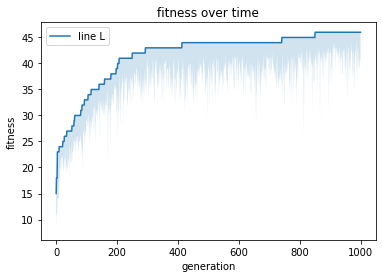

In [ ]:
import matplotlib.pyplot as plt

x  = range(1000)
plt.plot(x, max_fitnesses, label="line L")
plt.fill_between(x, min_fitnesses, max_fitnesses, alpha=0.2)
plt.plot()

plt.xlabel("generation")
plt.ylabel("fitness")
plt.title("fitness over time")
plt.legend()
plt.show()

Finally, because the recipe is always sorted according to fitness, the fittest individual will be the one in the first position, so we can print this out.

In [ ]:
pprint.PrettyPrinter(indent=2, depth=3).pprint(population[0])

{ 'fitness': 46,
  'ingredients': [ {'amount': 1, 'ingredient': 'baby potatoes', 'unit': 'g'},
                   {'amount': 1, 'ingredient': 'thyme', 'unit': 'g'},
                   {'amount': 1, 'ingredient': 'basil', 'unit': 'g'},
                   {'amount': 1, 'ingredient': 'onion powder', 'unit': 'g'},
                   {'amount': 1, 'ingredient': 'egg noodle', 'unit': 'g'},
                   {'amount': 1, 'ingredient': 'tomato', 'unit': 'g'},
                   {'amount': 1, 'ingredient': 'bacon', 'unit': 'g'},
                   {'amount': 1, 'ingredient': 'milk', 'unit': 'ml'},
                   {'amount': 1, 'ingredient': 'green bean', 'unit': 'ml'},
                   {'amount': 25, 'ingredient': 'carrot', 'unit': 'g'},
                   {'amount': 1, 'ingredient': 'garlic', 'unit': 'g'},
                   {'amount': 1, 'ingredient': 'cheese', 'unit': 'g'},
                   {'amount': 1, 'ingredient': 'black pepper', 'unit': 'ml'},
                   {'amount': 2, '